# Ultimate Technologies | Demand, toll reimbursement and rider retention


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 1. Aggregate logins in 15-minute intervals

In [2]:
Path("figures").mkdir(exist_ok=True)
events = pd.to_datetime(pd.read_json("data/logins.json").login_time, errors="raise")
counts = events.sort_values().to_frame("event").set_index("event").resample("15min").size()
assert counts.sum() == len(events)
print("Login coverage", events.min(), events.max(), "events", len(events),
      "extra identical timestamps", events.duplicated().sum(), "empty bins", counts.eq(0).sum())

Login coverage 1970-01-01 20:12:16 1970-04-13 18:57:38 events 93142 extra identical timestamps 877 empty bins 407


### Compare weekday and weekend demand

Weekday peak quarter index and mean 46 20.056338028169016
Weekend peak quarter index and mean 19 35.63333333333333
Mean bin by weekday (Monday=0) {0: 6.3, 1: 6.9, 2: 7.7, 3: 8.8, 4: 10.6, 5: 13.5, 6: 12.6}


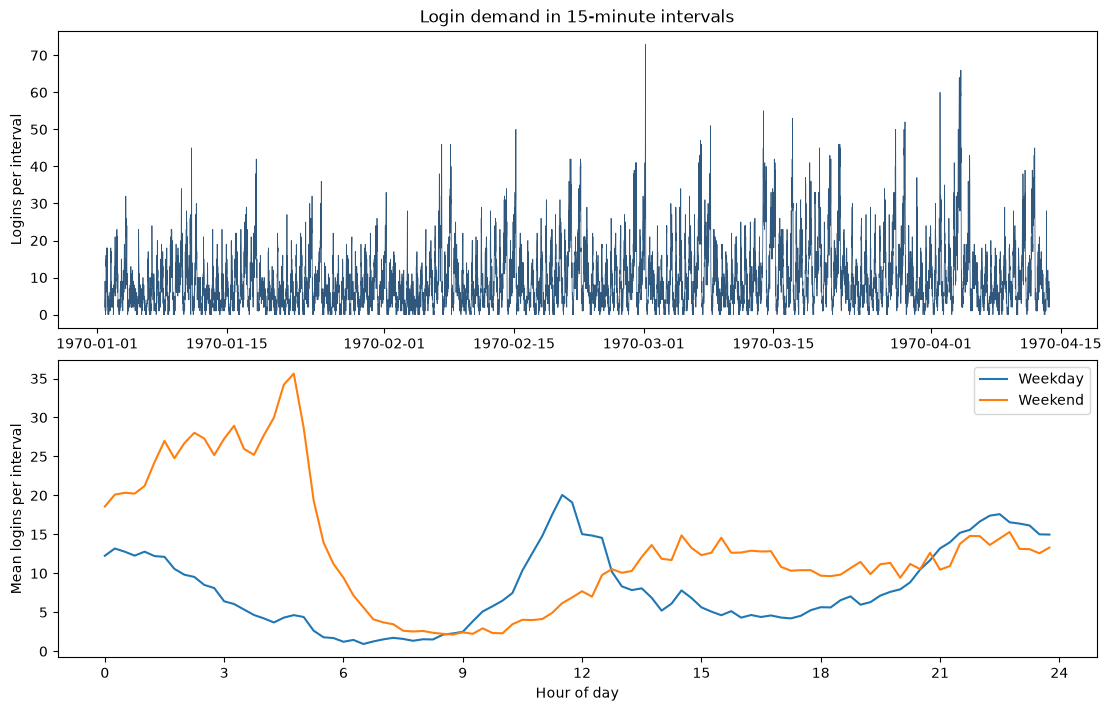

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), layout="constrained")
axes[0].plot(counts.index, counts, linewidth=.55, color="#30577c")
axes[0].set(title="Login demand in 15-minute intervals", ylabel="Logins per interval")
# Partial first and last dates distort time-of-day averages.
days = counts.index.normalize()
full = counts[(days > days.min()) & (days < days.max())]
profile = full.groupby([full.index.dayofweek >= 5, full.index.hour * 4 + full.index.minute // 15]).mean()
for weekend, label in [(False, "Weekday"), (True, "Weekend")]:
    series = profile.loc[weekend]
    axes[1].plot(series.index / 4, series, label=label)
    print(label, "peak quarter index and mean", series.idxmax(), series.max())
axes[1].set(xlabel="Hour of day", ylabel="Mean logins per interval", xticks=range(0, 25, 3))
axes[1].legend()
fig.savefig("figures/demand.png", dpi=145)
print("Mean bin by weekday (Monday=0)", full.groupby(full.index.dayofweek).mean().round(1).to_dict())
plt.show()

The file contains 93,142 logins between January 1 and April 13, 1970. Across complete dates, weekday demand peaks at 11:30 a.m. (20.1 logins per 15 minutes), while the weekend peak moves to 4:45 a.m. (35.6). Saturday averages 13.5 logins per interval across the entire day, more than double Monday’s 6.3. A staffing plan based on a single daily average would miss the early weekend surge. Logins measure app activity; completed trips would be needed to estimate ride demand directly.

## 2. Would reimbursing bridge tolls change driver behavior?

**Primary outcome.** For each eligible driver, calculate the fraction of pilot weeks in which they completed at least one pickup in each city. Average that fraction over all assigned drivers, including drivers with no pickups. A crossing with no passenger service earns no credit. Using a fixed denominator also captures any effect on whether drivers work.

**Pilot.** Enroll drivers who completed a ride in the four weeks before launch. Within home city and baseline cross-city activity strata, randomly assign drivers equally to automatic two-way toll reimbursement or existing terms. Run both arms on the same dates for at least four full weeks, link toll records to active driver accounts and record failed reimbursements. Before launch, use historical driver-week data to estimate the variance of the per-driver outcome and size the pilot for an agreed minimum worthwhile lift at 80% power and a two-sided 5% significance level.

**Analysis and decision.** Compare assignment groups by intention to treat. Estimate the within-stratum difference in mean driver outcomes, weighted by enrolled stratum size. Permute driver assignments within strata for a two-sided randomization test. Bootstrap drivers within strata and arms for a 95% interval. This preserves the dependence between weeks for the same driver. Track pickup wait times in each city, unserved requests, and reimbursement cost per additional driver-week of dual-city service. Expand if the estimated gain is economically worthwhile, its interval supports a positive effect, and both cities meet service and cost limits agreed before launch. An interval spanning negligible and worthwhile effects calls for more evidence. Drivers compete for the same rides, so check a phased market rollout for displacement before forecasting the full-scale gain.

## 3. Define retention and examine first-month predictors

In [4]:
riders = pd.read_json("data/ultimate_data_challenge.json")
last = pd.to_datetime(riders.last_trip_date)
snapshot = last.max()
y = last.gt(snapshot - pd.Timedelta(days=30)).astype(int)
print("Retained", y.sum(), len(y), y.mean(), "June 1 inclusive sensitivity", last.ge("2014-06-01").mean())
features = ["city", "trips_in_first_30_days", "avg_dist", "ultimate_black_user"]
X = riders[features]
assert X.notna().all().all()
for col in ["city", "ultimate_black_user","trips_in_first_30_days"]:
    groups = X[col].clip(upper=5) if col == "trips_in_first_30_days" else X[col]
    print(col, y.groupby(groups).agg(["size", "mean"]).round(3))

Retained 18310 50000 0.3662 June 1 inclusive sensitivity 0.37608
city                  size   mean
city                        
Astapor         16534  0.243
King's Landing  10130  0.623
Winterfell      23336  0.342
ultimate_black_user                       size   mean
ultimate_black_user              
False                31146  0.287
True                 18854  0.496
trips_in_first_30_days                          size   mean
trips_in_first_30_days              
0                       15390  0.347
1                       14108  0.216
2                        7402  0.361
3                        3788  0.438
4                        2562  0.505
5                        6750  0.636


### Compare two models on later signups

In [5]:
prep = ColumnTransformer([
    ("city", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["city"]),
    ("numbers", StandardScaler(), features[1:])])
# Preselect model families and evaluate on later signup dates.
train = riders.signup_date < "2014-01-25"
for estimator in [LogisticRegression(), HistGradientBoostingClassifier(max_leaf_nodes=12, random_state=41)]:
    model = make_pipeline(prep, estimator).fit(X[train], y[train])
    probabilities = model.predict_proba(X[~train])[:, 1]
    print(type(estimator).__name__, "test size/prevalence", (~train).sum(), y[~train].mean(),
          "ROC AUC", roc_auc_score(y[~train], probabilities), "AP",
          average_precision_score(y[~train], probabilities), "confusion at .5",
          confusion_matrix(y[~train], probabilities >= .5).tolist())
    if isinstance(estimator, HistGradientBoostingClassifier):
        importance = permutation_importance(model, X[~train], y[~train], scoring="roc_auc",
                                            n_repeats=5, random_state=41)
        print("AUC loss when shuffled", dict(zip(features, importance.importances_mean.round(4))))

LogisticRegression test size/prevalence 11881 0.3676458210588334 ROC AUC 0.7264208765855911 AP 0.6152109544869584 confusion at .5 [[6513, 1000], [2498, 1870]]
HistGradientBoostingClassifier test size/prevalence 11881 0.3676458210588334 ROC AUC 0.7606936743100725 AP 0.6472311264422055 confusion at .5 [[6436, 1077], [2268, 2100]]
AUC loss when shuffled {'city': np.float64(0.0987), 'trips_in_first_30_days': np.float64(0.063), 'avg_dist': np.float64(0.0442), 'ultimate_black_user': np.float64(0.0411)}


**Outcome.** January signups form a cohort of 50,000 riders. Using July 1 (the latest recorded trip) as the final observed date, 18,310 riders, or **36.62%**, took a trip during June 2–July 1 inclusive. Counting June 1 as well gives 37.61%. This snapshot approximates month-six activity. Exact rider-relative sixth-month labels require dated trip histories.

**Predictors.** The model uses signup city, first-30-day trips, first-30-day average distance and first-30-day Ultimate Black use. All four are complete. Lifetime ratings, weekday mix and surge measures may include future trips. Phone is recorded as the primary device without a dated snapshot. We excluded these variables. Retention ranged from 24.3% in Astapor to 62.3% in King’s Landing. Among riders with one first-month trip, 21.6% were retained, compared with 63.6% for five or more. The zero-trip group retained at 34.7%, so risk does not change linearly with trip count.

The first 24 signup dates trained the models; the final seven dates supplied 11,881 held-out riders. Boosting can learn the non-monotonic trip relationship. At a 0.50 retention threshold it identified 2,102 of 4,368 retained riders (48.1% recall, 66.1% precision). Shuffling city reduced held-out AUC by 0.099, followed by first-month trip count (0.063), distance (0.044) and Black use (0.041). These estimates reflect one cohort and a retrospective split. A later cohort with completed follow-up is needed to test prospective validity.

**Action.** At day 30, pilot a second-ride offer among one-trip riders. Randomize the offer within city and compare incremental retained riders and contribution margin after incentive costs. City differences can guide investigation into pickup reliability and supply. The 49.6% vs 28.7% retention gap by Black use alone cannot establish that upgrading a rider would improve retention.